In [2]:
import pandas as pd
import numpy as np

def load_data(file_path):
    """
    Load data from a CSV file into a pandas DataFrame.

    Parameters:
    file_path (str): The path to the CSV file.

    Returns:
    pd.DataFrame: A DataFrame containing the loaded data.
    """
    try:
        data = pd.read_csv(file_path)
        return data
    except Exception as e:
        print(f"Error loading data: {e}")
        return None

In [3]:
loaded_data = load_data('D:\\Personal\\ecommerce_analysis_project\\ecommerce_analysis_project\\data\\ecommerce_orders.csv')


In [4]:
loaded_data.head()
df = pd.DataFrame(loaded_data)


In [5]:
south= loaded_data[loaded_data['region'] == 'South']
south


,order_id,order_date,customer_id,product_id,product_name,category,region,quantity,unit_price,discount_pct,payment_mode
0,ORD00001,2025-02-01,CUST0175,P001,Wireless Mouse,Electronics,South,4,641.96,0.05,UPI
3,ORD00004,2025-11-10,CUST0207,P005,Desk Lamp,Home,South,1,911.85,0.10,Net Banking
11,ORD00012,2025-01-14,CUST0035,P003,USB-C Hub,Electronics,South,4,1925.11,0.05,UPI
16,ORD00017,2025-04-28,CUST0042,P010,Coffee Maker,Home,South,3,3506.19,0.05,UPI
18,ORD00019,2025-03-02,CUST0096,P010,Coffee Maker,Home,South,1,3263.47,0.10,Credit Card
...,...,...,...,...,...,...,...,...,...,...,...
1183,ORD01184,2025-10-18,CUST0218,P006,Notebook Set,Stationery,South,3,262.80,0.10,Credit Card
1184,ORD01185,2025-10-28,CUST0076,P006,Notebook Set,Stationery,South,2,261.29,0.00,Debit Card
1185,ORD01186,2025-08-23,CUST0220,P005,Desk Lamp,Home,South,1,1062.39,0.15,UPI
1191,ORD01192,2025-06-03,CUST0168,P003,USB-C Hub,Electronics,South,3,1737.69,0.05,Credit Card


In [6]:
loaded_data.count()

order_id        1200
order_date      1200
customer_id     1200
product_id      1200
product_name    1200
category        1200
region          1198
quantity        1200
unit_price      1200
discount_pct    1199
payment_mode    1199
dtype: int64

In [7]:
loaded_data.shape

(1200, 11)

In [8]:
south.shape

(238, 11)

In [9]:
# south_total_sales = south.quantity*south.unit_price
# print(south_total_sales.sum())\

south_total_sales = south["quantity"] * south["unit_price"]

south_discount = south_total_sales * south["discount_pct"]

south_net_sales = south_total_sales - south_discount

print("South Gross Sales:", south_total_sales.sum())
print("South Total Discount:", south_discount.sum())
print("South Net Sales:", south_net_sales.sum())
# print("South Net Sales:", south_net_sales)

South Gross Sales: 741753.9500000001
South Total Discount: 44590.90950000001
South Net Sales: 693337.6205


In [10]:
south_payment_method_counts = south['payment_mode'].value_counts()
south_payment_method_counts

payment_mode
UPI                 51
Credit Card         50
Debit Card          50
Net Banking         47
Cash on Delivery    40
Name: count, dtype: int64

In [11]:
# south_payment_method_counts = south[south['payment_mode'] == 'UPI'].value_counts()
south_upi_count = (south["payment_mode"] == "UPI").sum()

print("Total UPI Transactions in South:", south_upi_count)

Total UPI Transactions in South: 51


In [12]:
# DATE 

from datetime import date


# date = pd.to_datetime(south['order_date'], format='%Y-%m-%d')

df["order_date"] = pd.to_datetime(df["order_date"], format='%Y-%m-%d')

first_date = df["order_date"].min()
last_date = df["order_date"].max()

print("First Date:", first_date)
print("Last Date:", last_date)


First Date: 2025-01-01 00:00:00
Last Date: 2025-12-31 00:00:00


In [13]:
# North region analysis

north = loaded_data[loaded_data['region'] == 'North']

north_total_sales = north["quantity"] * north["unit_price"]

north_discount = north_total_sales * north["discount_pct"]

north_net_sales = north_total_sales - north_discount

print("North Gross Sales:", north_total_sales.sum())
print("North Total Discount:", north_discount.sum())
print("North Net Sales:", north_net_sales.sum())

North Gross Sales: 731402.98
North Total Discount: 46774.6975
North Net Sales: 684628.2825


In [14]:
! pip install matplotlib


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Net Sales: 684628.2825 693337.6205


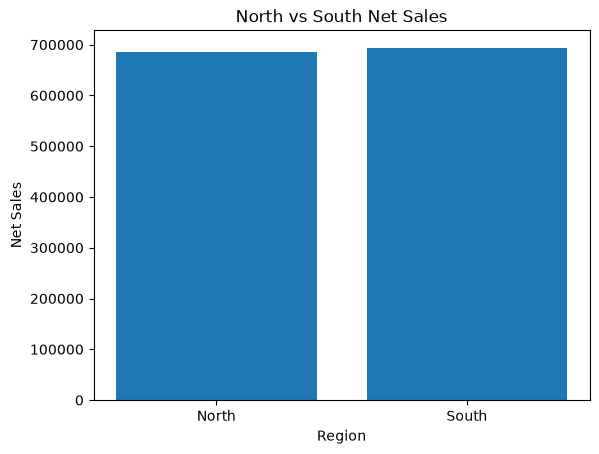

In [15]:
import matplotlib.pyplot as plt

# plt.bar(north_net_sales,south_net_sales)

# plt.title("North vs South Net Sales")
# plt.xlabel("Region")
# plt.ylabel("Net Sales")
# plt.show()

regions = ["North", "South"]

net_sales = [
    north_net_sales.sum(),
    south_net_sales.sum()
]
print("Net Sales:", north_net_sales.sum(), south_net_sales.sum())

plt.bar(regions, net_sales)

plt.title("North vs South Net Sales")
plt.xlabel("Region")
plt.ylabel("Net Sales")
plt.show()


In [16]:
x=df.product_name.unique()
print("Unique Products:", x)
print("Total Unique Products:", x.count())

Unique Products: <StringArray>
['Wireless Mouse',   'Notebook Set',      'Desk Lamp',       'Keyboard',
        'T-Shirt',   'Coffee Maker',  'Running Shoes',      'USB-C Hub',
       'Backpack',   'Water Bottle']
Length: 10, dtype: str
Total Unique Products: 10


In [17]:
# df.region.unique()
# print("Unique Regions:", y)
df[["region"]].drop_duplicates()

,region
0,South
1,Central
2,East
4,West
6,North
13,NaN


In [18]:
df[["product_id", "product_name"]].drop_duplicates().reset_index(drop=True)




,product_id,product_name
0,P001,Wireless Mouse
1,P006,Notebook Set
2,P005,Desk Lamp
3,P002,Keyboard
4,P008,T-Shirt
5,P010,Coffee Maker
6,P009,Running Shoes
7,P003,USB-C Hub
8,P007,Backpack
9,P004,Water Bottle


In [19]:
df["region"].drop_duplicates()

0       South
1     Central
2        East
4        West
6       North
13        NaN
Name: region, dtype: str

In [20]:
category_names = df[["category"]].drop_duplicates().reset_index(drop=True)
print(category_names.count())
print(len(category_names))
category_names


category    4
dtype: int64
4


,category
0,Electronics
1,Stationery
2,Home
3,Fashion


In [21]:
df["category"].unique()

<StringArray>
['Electronics', 'Stationery', 'Home', 'Fashion']
Length: 4, dtype: str

In [22]:
# East region analysis

east = loaded_data[loaded_data['region'] == 'East']
east_total_sales = east["quantity"] * east["unit_price"]

east_discount = east_total_sales * east["discount_pct"]

east_net_sales = east_total_sales - east_discount

print("East Gross Sales:", east_total_sales.sum())
print("East Total Discount:", east_discount.sum())
print("East Net Sales:", east_net_sales.sum())


East Gross Sales: 810226.36
East Total Discount: 50764.473
East Net Sales: 759461.8869999999


In [23]:
# Central region analysis
central = loaded_data[loaded_data['region'] == 'Central']
central_total_sales = central["quantity"] * central["unit_price"]
central_discount = central_total_sales * central["discount_pct"]
central_net_sales = central_total_sales - central_discount

print("Central Gross Sales:", central_total_sales.sum())
print("Central Total Discount:", central_discount.sum())
print("Central Net Sales:", central_net_sales.sum())

Central Gross Sales: 763378.8
Central Total Discount: 47972.6835
Central Net Sales: 715406.1165


In [24]:
# West region analysis
west = loaded_data[loaded_data['region'] == 'West']
west_total_sales = west["quantity"] * west["unit_price"]
west_discount = west_total_sales * west["discount_pct"]
west_net_sales = west_total_sales - west_discount

print("West Gross Sales:", west_total_sales.sum())
print("West Total Discount:", west_discount.sum())
print("West Net Sales:", west_net_sales.sum())

West Gross Sales: 890568.8800000001
West Total Discount: 65518.08500000001
West Net Sales: 825050.7949999999


North Net Sales: 684628.2825
South Net Sales: 693337.6205
East Net Sales: 759461.8869999999
Central Net Sales: 715406.1165
West Net Sales: 825050.7949999999


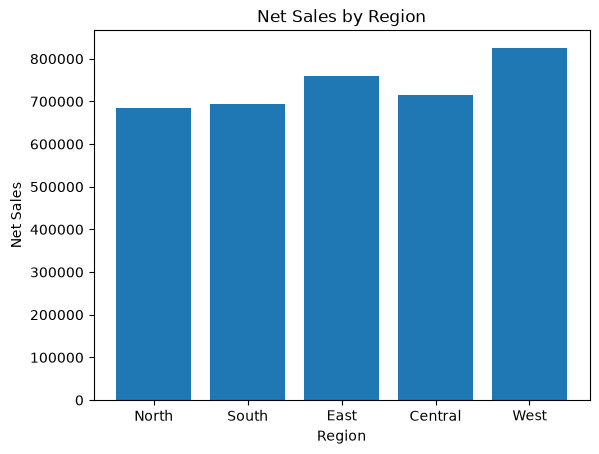

In [25]:
import matplotlib.pyplot as plt

# plt.bar(north_net_sales,south_net_sales)

# plt.title("North vs South Net Sales")
# plt.xlabel("Region")
# plt.ylabel("Net Sales")
# plt.show()

regions = ["North", "South", "East", "Central", "West"]

net_sales = [
    north_net_sales.sum(),
    south_net_sales.sum(),
    east_net_sales.sum(),
    central_net_sales.sum(),
    west_net_sales.sum()
]

print("North Net Sales:", north_net_sales.sum())
print("South Net Sales:", south_net_sales.sum())
print("East Net Sales:", east_net_sales.sum())
print("Central Net Sales:", central_net_sales.sum())
print("West Net Sales:", west_net_sales.sum())
plt.bar(regions, net_sales)

plt.title("Net Sales by Region")
plt.xlabel("Region")
plt.ylabel("Net Sales")
plt.show()

In [26]:
# Monthly sales

january_sales = df[df["order_date"].dt.month == 1]
february_sales = df[df["order_date"].dt.month == 2]
march_sales = df[df["order_date"].dt.month == 3]
april_sales = df[df["order_date"].dt.month == 4]
may_sales = df[df["order_date"].dt.month == 5]
june_sales = df[df["order_date"].dt.month == 6]
july_sales = df[df["order_date"].dt.month == 7]
august_sales = df[df["order_date"].dt.month == 8]
september_sales = df[df["order_date"].dt.month == 9]
october_sales = df[df["order_date"].dt.month == 10]
november_sales = df[df["order_date"].dt.month == 11]
december_sales = df[df["order_date"].dt.month == 12]


january_net_sales = (january_sales["quantity"] * january_sales["unit_price"]) - (january_sales["quantity"] * january_sales["unit_price"] * january_sales["discount_pct"])
february_net_sales = (february_sales["quantity"] * february_sales["unit_price"]) - (february_sales["quantity"] * february_sales["unit_price"] * february_sales["discount_pct"])
march_net_sales = (march_sales["quantity"] * march_sales["unit_price"]) - (march_sales["quantity"] * march_sales["unit_price"] * march_sales["discount_pct"])
april_net_sales = (april_sales["quantity"] * april_sales["unit_price"]) - (april_sales["quantity"] * april_sales["unit_price"] * april_sales["discount_pct"])
may_net_sales = (may_sales["quantity"] * may_sales["unit_price"]) - ( may_sales["quantity"] * may_sales["unit_price"] * may_sales["discount_pct"])
june_net_sales = (june_sales["quantity"] * june_sales["unit_price"]) - (june_sales["quantity"] * june_sales["unit_price"] * june_sales["discount_pct"])
july_net_sales = (july_sales["quantity"] * july_sales["unit_price"]) - (july_sales["quantity"] * july_sales["unit_price"] * july_sales["discount_pct"])
august_net_sales = (august_sales["quantity"] * august_sales["unit_price"]) - (august_sales["quantity"] * august_sales["unit_price"] * august_sales["discount_pct"])
september_net_sales = (september_sales["quantity"] * september_sales["unit_price"]) - (september_sales["quantity"] * september_sales["unit_price"] * september_sales["discount_pct"])
october_net_sales = (october_sales["quantity"] * october_sales["unit_price"]) - (october_sales["quantity"] * october_sales["unit_price"] * october_sales["discount_pct"])
november_net_sales = (november_sales["quantity"] * november_sales["unit_price"]) - (november_sales["quantity"] * november_sales["unit_price"] * november_sales["discount_pct"])
december_net_sales = (december_sales["quantity"] * december_sales["unit_price"]) - (december_sales["quantity"] * december_sales["unit_price"] * december_sales["discount_pct"]) 

print("January Net Sales:", january_net_sales.sum())
print("February Net Sales:", february_net_sales.sum())
print("March Net Sales:", march_net_sales.sum())
print("April Net Sales:", april_net_sales.sum())
print("May Net Sales:", may_net_sales.sum())
print("June Net Sales:", june_net_sales.sum())
print("July Net Sales:", july_net_sales.sum())
print("August Net Sales:", august_net_sales.sum())
print("September Net Sales:", september_net_sales.sum())
print("October Net Sales:", october_net_sales.sum())
print("November Net Sales:", november_net_sales.sum())
print("December Net Sales:", december_net_sales.sum())

January Net Sales: 269504.059
February Net Sales: 271075.64550000004
March Net Sales: 252317.34
April Net Sales: 362228.15799999994
May Net Sales: 320951.28450000007
June Net Sales: 310294.7345
July Net Sales: 396866.709
August Net Sales: 260083.69900000002
September Net Sales: 338834.05900000007
October Net Sales: 327931.7540000001
November Net Sales: 302553.42149999994
December Net Sales: 268398.22550000006


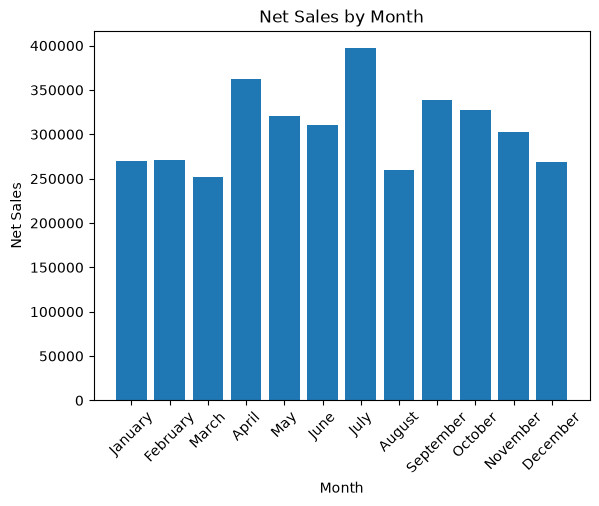

In [27]:
import matplotlib.pyplot as plt

months = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]

net_sales = [
    january_net_sales.sum(),
    february_net_sales.sum(),
    march_net_sales.sum(),
    april_net_sales.sum(),
    may_net_sales.sum(),
    june_net_sales.sum(),
    july_net_sales.sum(),
    august_net_sales.sum(),
    september_net_sales.sum(),
    october_net_sales.sum(),
    november_net_sales.sum(),
    december_net_sales.sum()
]

plt.bar(months, net_sales)

plt.title("Net Sales by Month")
plt.xlabel("Month")
plt.ylabel("Net Sales")
plt.xticks(rotation=45)
plt.show()

In [28]:
# Unique products by category

unique_products_by_category = df.groupby('category')['product_name'].nunique().reset_index()

unique_products_by_category


,category,product_name
0,Electronics,3
1,Fashion,3
2,Home,3
3,Stationery,1


In [29]:
# category names with unique product names

category_product_names = df.groupby('category')['product_name'].unique().reset_index()
category_product_names

,category,product_name
0,Electronics,"[Wireless Mouse, Keyboard, USB-C Hub]"
1,Fashion,"[T-Shirt, Running Shoes, Backpack]"
2,Home,"[Desk Lamp, Coffee Maker, Water Bottle]"
3,Stationery,[Notebook Set]


      category  quantity
0  Electronics       946
2         Home       871
1      Fashion       845
3   Stationery       319


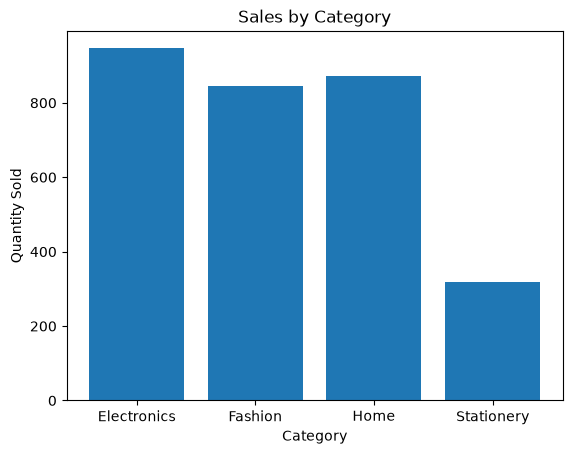

In [30]:
# sales by category 
sales_by_category = df.groupby('category')['quantity'].sum().reset_index()
print(sales_by_category.sort_values(by='quantity', ascending=False))
# sales_by_category

plt.bar(sales_by_category['category'], sales_by_category['quantity'])
plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Quantity Sold")
plt.show()

     product_name  quantity
8    Water Bottle       326
3        Keyboard       322
4    Notebook Set       319
7       USB-C Hub       317
9  Wireless Mouse       307
0        Backpack       300
1    Coffee Maker       283
6         T-Shirt       275
5   Running Shoes       270
2       Desk Lamp       262


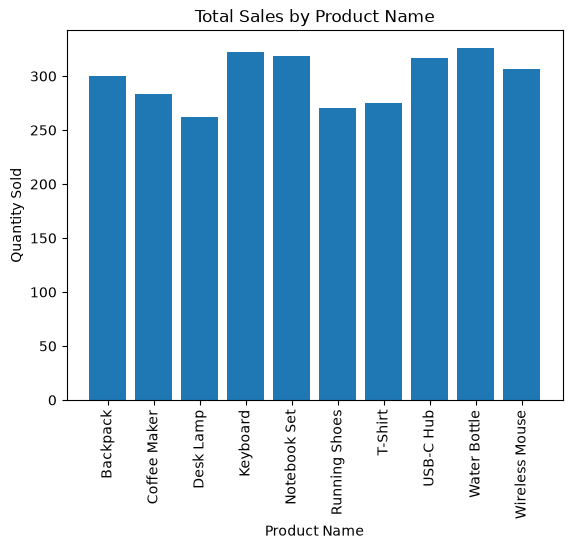

In [31]:
# total sales by product name
total_sales_by_product = df.groupby('product_name')['quantity'].sum().reset_index() 
print(total_sales_by_product.sort_values(by='quantity', ascending=False))
plt.bar(total_sales_by_product['product_name'], total_sales_by_product['quantity'])
plt.title("Total Sales by Product Name")
plt.xlabel("Product Name")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=90)
plt.show()

In [32]:
# total sales by product name and category
total_sales_by_product_category = df.groupby(['category', 'product_name'])['quantity'].sum().reset_index()
print(total_sales_by_product_category.sort_values(by='quantity', ascending=False))

      category    product_name  quantity
8         Home    Water Bottle       326
0  Electronics        Keyboard       322
9   Stationery    Notebook Set       319
1  Electronics       USB-C Hub       317
2  Electronics  Wireless Mouse       307
3      Fashion        Backpack       300
6         Home    Coffee Maker       283
5      Fashion         T-Shirt       275
4      Fashion   Running Shoes       270
7         Home       Desk Lamp       262
